# TSFM4NILM : Sequence-to-Point Energy Disaggregation Using MOMENT

## Data splits

### Cleaned Data source : https://pureportal.strath.ac.uk/en/datasets/refit-electrical-load-measurements-cleaned/

### Segmented Dataset Specifics :

**Naming scheme:** House 1 to House 21 (without House 14).

**Dataset format:** DateTime (YYYY-MM-DD HH:mm:ss), UNIX TIMESTAMP (UCT), Aggregate, Appliance1, Appliance2, ... , Appliance9.

**Solar planel:** House 11 and 21 aggregates are affected by solar panels, not using them.

**Issues(boolean):** Rows where the sum of appliance powers > aggregate power identified as majorily as dead aggregates and handled by removing them

**Segmentation** Gaps in sampling > 2min segmented such that every input window doesn't have long gaps between sequence of data.

**Target appliances** : For this experiment, we are looking only at kettle, fridge-freezer and washing machine.







## Imports

In [ ]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SEGMENTED_DIR = Path("segmented")
TARGETS = ["Kettle", "Fridge-Freezer", "Washing Machine"]
NON_APPLIANCE = ("House", "Time", "Unix", "Aggregate", "Issues", "Segment")

# House ids from the saved files, e.g. SEGMENTED_HOUSE12.csv -> 12
HOUSES = sorted(int(p.stem.removeprefix("SEGMENTED_HOUSE")) for p in SEGMENTED_DIR.glob("SEGMENTED_HOUSE*.csv"))


def house_file(house_id):
    return SEGMENTED_DIR / f"SEGMENTED_HOUSE{house_id}.csv"

## Exploring appliance distribution

### Common appliances

Counts how many houses have each appliance, read from the file headers only. Suffixes like " (1)" or " (Garage)" are stripped, so e.g. house 16's Fridge-Freezer (1) and (2) count as one Fridge-Freezer for that house.

Tells us which houses can be used for each target appliance.

In [9]:
SEGMENTED_DIR = Path("segmented")
TARGETS = ["Kettle", "Fridge-Freezer", "Washing Machine"]
NON_APPLIANCE = ("House", "Time", "Unix", "Aggregate", "Issues", "Segment")

# House ids from the saved files, e.g. SEGMENTED_HOUSE12.csv -> 12
HOUSES = sorted(int(p.stem.removeprefix("SEGMENTED_HOUSE")) for p in SEGMENTED_DIR.glob("SEGMENTED_HOUSE*.csv"))


def house_file(house_id):
    return SEGMENTED_DIR / f"SEGMENTED_HOUSE{house_id}.csv"

# Appliance columns per house, read from the file headers only (nrows=0)
house_columns = {h: [c for c in pd.read_csv(house_file(h), nrows=0).columns if c not in NON_APPLIANCE]
                 for h in HOUSES}

# Strip suffixes like " (1)" or " (Garage)" so each appliance counts once per house
house_appliances = {h: {c.split(" (")[0] for c in cols} for h, cols in house_columns.items()}

# Number of houses each appliance appears in
appliance_counts = pd.Series([a for names in house_appliances.values() for a in names]).value_counts()
display(appliance_counts.to_frame("Houses"))

# Houses that have each target appliance
for target in TARGETS:
    houses = [h for h, names in house_appliances.items() if target in names]
    print(f"{target} ({len(houses)} houses): {houses}")

,Houses
Washing Machine,17
Television Site,16
Kettle,14
Microwave,14
Dishwasher,13
Fridge-Freezer,11
Toaster,9
Freezer,9
Tumble Dryer,8
Computer Site,8


Kettle (14 houses): [2, 3, 4, 5, 6, 7, 8, 9, 12, 13, 15, 17, 19, 20]
Fridge-Freezer (11 houses): [2, 3, 4, 5, 9, 10, 12, 15, 16, 17, 18]
Washing Machine (17 houses): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13, 15, 16, 17, 18, 19, 20]


### Target activity per house

Counts how often each target appliance is actually used in each house that has it.

- **On:** the channel reads at least the on threshold (Kettle 2000 W, Fridge-Freezer 50 W, Washing Machine 20 W).
- **Activation:** a run of on readings. A new one starts after an off gap longer than 1 min (30 min for the washing machine, so pauses within one wash cycle don't split it), or in a new segment.
- **Per day:** activations divided by the house's usable days, so houses with different amounts of data can be compared.

Tells us which houses have enough target events to be used for training, validation or test, and how imbalanced on vs. off is.

In [10]:
# On threshold (W) and the off gap that separates two activations
ACTIVITY = {
    "Kettle":          {"on_power": 2000, "min_off": pd.Timedelta("1min")},
    "Fridge-Freezer":  {"on_power": 50,   "min_off": pd.Timedelta("1min")},
    "Washing Machine": {"on_power": 20,   "min_off": pd.Timedelta("30min")},  # merges pauses within one wash cycle
}

rows = []
for house_id in HOUSES:
    target_cols = [c for c in house_columns[house_id] if c.split(" (")[0] in TARGETS]
    if not target_cols:
        continue
    # Only the columns needed here, to keep loading light
    df = pd.read_csv(house_file(house_id), usecols=["Time", "Segment", *target_cols], parse_dates=["Time"])

    seg_time = df.groupby("Segment")["Time"].agg(["min", "max"])
    days = (seg_time["max"] - seg_time["min"]).sum() / pd.Timedelta("1D")

    for col in target_cols:
        target = col.split(" (")[0]
        on = df[col] >= ACTIVITY[target]["on_power"]
        on_rows = df.loc[on, ["Time", "Segment"]]

        # A new activation starts after an off gap > min_off, or in a new segment
        starts = ((on_rows["Time"].diff() > ACTIVITY[target]["min_off"])
                  | (on_rows["Segment"] != on_rows["Segment"].shift()))

        rows.append({"Target": target, "House": house_id, "Channel": col, "Usable days": days,
                     "Activations": int(starts.sum()), "Per day": starts.sum() / days, "% time on": on.mean()})

activity = pd.DataFrame(rows)

for target in TARGETS:
    print(target)
    display(activity[activity["Target"] == target].drop(columns="Target").set_index("House")
            .sort_values("Activations", ascending=False)
            .style.format({"Usable days": "{:.0f}", "Activations": "{:,}", "Per day": "{:.1f}", "% time on": "{:.2%}"}))

Kettle


,Channel,Usable days,Activations,Per day,% time on
House,,,,,
5,Kettle,583,"4,192",7.2,0.81%
6,Kettle,464,"4,077",8.8,0.92%
17,Kettle,432,"3,409",7.9,0.78%
8,Kettle,491,"3,403",6.9,0.75%
2,Kettle,462,"3,367",7.3,0.85%
9,Kettle,478,"3,148",6.6,1.00%
12,Kettle,453,"2,614",5.8,0.84%
19,Kettle,438,"2,535",5.8,0.51%
20,Kettle,432,"1,880",4.3,0.47%


Fridge-Freezer


,Channel,Usable days,Activations,Per day,% time on
House,,,,,
5,Fridge-Freezer,583,"26,911",46.2,50.31%
18,Fridge-Freezer,399,"20,229",50.7,49.12%
9,Fridge-Freezer,478,"16,230",34.0,48.87%
4,Fridge-Freezer,541,"16,010",29.6,28.89%
10,Fridge-Freezer,495,"9,993",20.2,19.37%
16,Fridge-Freezer (2),440,"9,877",22.4,20.86%
17,Fridge-Freezer,432,"9,260",21.4,35.78%
15,Fridge-Freezer,486,"9,117",18.8,31.18%
2,Fridge-Freezer,462,"8,586",18.6,39.75%


Washing Machine


,Channel,Usable days,Activations,Per day,% time on
House,,,,,
5,Washing Machine,583,"1,013",1.7,7.02%
7,Washing Machine,532,949,1.8,6.90%
10,Washing Machine,495,668,1.3,7.37%
3,Washing Machine,432,651,1.5,4.21%
17,Washing Machine,432,487,1.1,1.86%
8,Washing Machine,491,460,0.9,2.89%
13,Washing Machine,373,451,1.2,4.05%
1,Washing Machine,556,449,0.8,1.65%
15,Washing Machine,486,366,0.8,2.44%


### Activations per house

Activations per usable day for each target, one panel per target (each with its own scale). Labels show per-day rate and total activations.

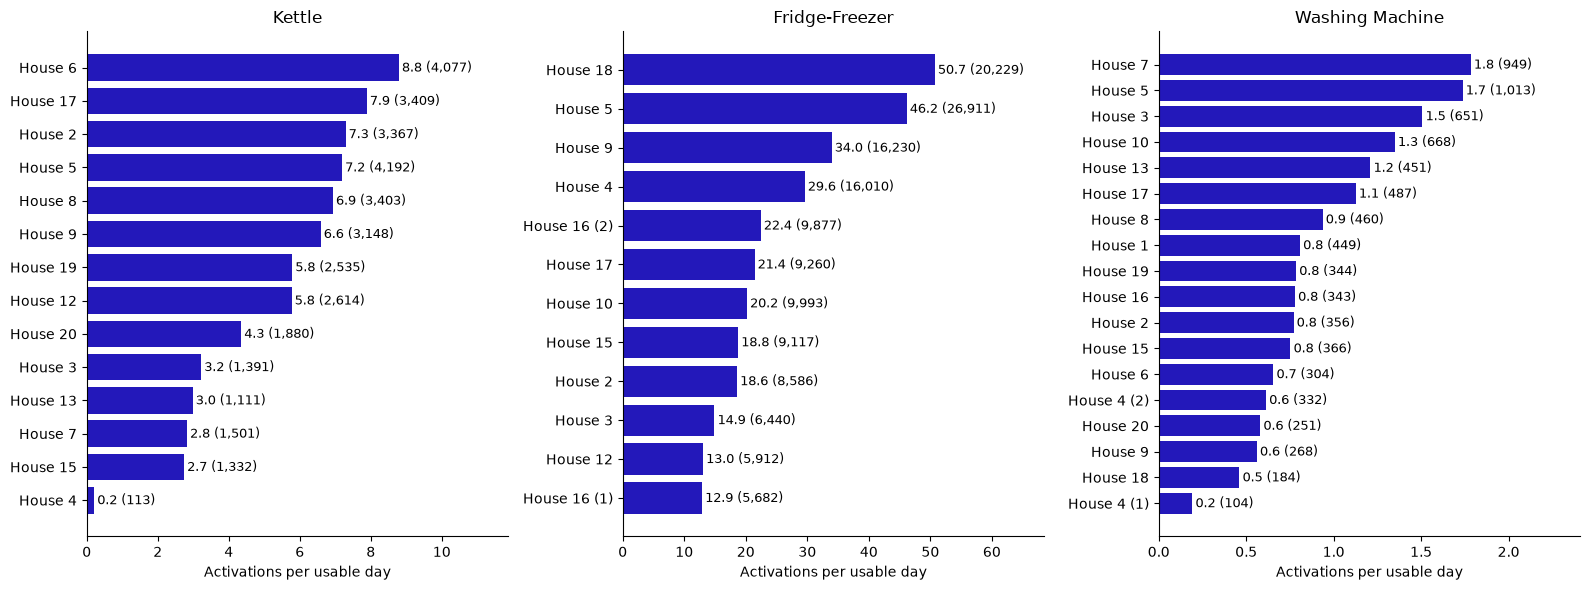

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, target in zip(axes, TARGETS):
    t = activity[activity["Target"] == target].sort_values("Per day")  # ascending so the highest bar ends up on top
    # Label by house, plus the channel suffix where a house has two channels of the target (e.g. house 16)
    labels = [f"House {h}{c.removeprefix(target)}" for h, c in zip(t["House"], t["Channel"])]

    ax.barh(labels, t["Per day"], color="#2318BA")
    for i, (v, n) in enumerate(zip(t["Per day"], t["Activations"])):
        ax.text(v + t["Per day"].max() * 0.01, i, f"{v:.1f} ({n:,})", va="center", fontsize=9)
    ax.set(xlabel="Activations per usable day", xlim=(0, t["Per day"].max() * 1.35), title=target)  # extra room for labels
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## Findings

**Target activity**

- **Kettle:** used 2.7–8.8 times per day in every house except **house 4** (0.2/day, 0.00% time on), whose kettle effectively never goes above 2 kW. House 4 is excluded.
- **Fridge-Freezer:** always active (13–51 activations/day, on 19–53% of the time). Houses **2, 5, 9, 12 and 15** are the only ones where it is the only cold appliance; houses 3, 4, 10, 17 and 18 also have a Fridge or Freezer that looks similar in the aggregate, and house 16 has two Fridge-Freezers.
- **Washing Machine:** the sparsest target (0.2–1.8 cycles/day). **House 18** has the fewest cycles of any single-machine house (184) and is the fault-heavy house from the EDA; **house 4** has two machines. Both are excluded.

**Split choices**

**Kettle** 

| Role | Houses | Activations |
|---|---|---|
| Train | 3, 6, 7, 8, 9, 12, 13, 19, 20 | 21,660 |
| Val | 5 | 4,192 |
| Test | 2, 15, 17 | 3,367 / 1,332 / 3,409 |

**Fridge-Freezer** 

| Role | Houses | Activations |
|---|---|---|
| Train | 2, 5, 9 | 51,727 |
| Val | 12 | 5,912 |
| Test | 15 | 9,117 |

**Washing Machine** 

| Role | Houses | Activations |
|---|---|---|
| Train | 2, 5, 7, 9, 15, 16, 17 | 3,782 |
| Val | 1 | 449 |
| Test | 3, 6, 8, 10, 13, 19, 20 | 651 / 304 / 460 / 668 / 451 / 344 / 251 |

## Splitting the data

Writes each target's houses to `splits/<target>/<train|val|test>/`, following the above tables 

Each file keeps only what the model needs: the aggregate (input), the target channel (label), the segment id (so windows stay within a segment), and the house/time columns for traceability. This keeps the files small, since some houses appear under more than one target.

A check also confirms that no house is in more than one role for the same target.

In [13]:
SPLITS_DIR = Path("splits")

# Houses per role for each target, from the findings above
SPLITS = {
    "Kettle":          {"train": [3, 6, 7, 8, 9, 12, 13, 19, 20], "val": [5],  "test": [2, 15, 17]},
    "Fridge-Freezer":  {"train": [2, 5, 9],                       "val": [12], "test": [15]},
    "Washing Machine": {"train": [2, 5, 7, 9, 15, 16, 17],        "val": [1],  "test": [3, 6, 8, 10, 13, 19, 20]},
}

for target, roles in SPLITS.items():
    # No house may be in more than one role for the same target
    all_houses = sum(roles.values(), [])
    assert len(all_houses) == len(set(all_houses)), f"{target}: a house is in more than one split"

    for role, houses in roles.items():
        role_dir = SPLITS_DIR / target / role
        role_dir.mkdir(parents=True, exist_ok=True)

        for house_id in houses:
            # Only the aggregate input, the target label, the segment id and traceability columns
            df = pd.read_csv(house_file(house_id), usecols=["House", "Time", "Unix", "Aggregate", target, "Segment"])
            df.to_csv(role_dir / f"SEGMENTED_HOUSE{house_id}.csv", index=False)
            print(f"{target} / {role}: house {house_id} ({len(df):,} rows)")

Kettle / train: house 3 (5,518,870 rows)
Kettle / train: house 6 (5,941,607 rows)
Kettle / train: house 7 (6,704,393 rows)
Kettle / train: house 8 (6,031,033 rows)
Kettle / train: house 9 (6,136,263 rows)
Kettle / train: house 12 (5,849,947 rows)
Kettle / train: house 13 (4,590,984 rows)
Kettle / train: house 19 (5,597,903 rows)
Kettle / train: house 20 (5,160,904 rows)
Kettle / val: house 5 (7,392,501 rows)
Kettle / test: house 2 (5,697,034 rows)
Kettle / test: house 15 (6,197,907 rows)
Kettle / test: house 17 (5,330,268 rows)
Fridge-Freezer / train: house 2 (5,697,034 rows)
Fridge-Freezer / train: house 5 (7,392,501 rows)
Fridge-Freezer / train: house 9 (6,136,263 rows)
Fridge-Freezer / val: house 12 (5,849,947 rows)
Fridge-Freezer / test: house 15 (6,197,907 rows)
Washing Machine / train: house 2 (5,697,034 rows)
Washing Machine / train: house 5 (7,392,501 rows)
Washing Machine / train: house 7 (6,704,393 rows)
Washing Machine / train: house 9 (6,136,263 rows)
Washing Machine / trai